# Nearest-neighbour ion-pair lifetimes

This notebook generates the manuscript-style temperature plot from the portable seed-level table in `../data`. The reported lifetime is the direct first re-forming $C(t)=e^{-1}$ crossing; error bars are the sample standard deviation across seeds. A temperature with one or more non-crossing trajectories is shown only as a lower bound.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

chapter = Path.cwd().resolve()
if chapter.name == 'notebooks':
    chapter = chapter.parent
seed = pd.read_csv(chapter / 'data' / 'nearest_neighbor_tau_1e_all_forcefields_by_seed.csv')
figures = chapter / 'figures'
figures.mkdir(exist_ok=True)

# Exact density-chapter palette and display order.
colours = {'so3lr': '#ed7d31', 'apple': '#0078b8', 'opls': '#009e73', 'scaled_opls': '#c83817'}
markers = {'apple': 'o', 'so3lr': 'o', 'opls': 'o', 'scaled_opls': 'o'}
labels = {'apple': 'APPLE&P', 'so3lr': 'SO3LR', 'opls': 'CL&P', 'scaled_opls': 'CL&P-scaled'}
order = ['opls', 'so3lr', 'scaled_opls', 'apple']
temps = [290, 300, 310, 320, 330]
plt.rcParams.update({'font.size': 14, 'font.family': 'sans-serif', 'axes.labelsize': 16,
                     'xtick.labelsize': 14, 'ytick.labelsize': 14, 'axes.linewidth': 1.5,
                     'lines.linewidth': 2.5, 'lines.markersize': 8})


/home/akryachkova/ams2025.106/bin/python3.8/lib/python3.8/site-packages/mpl_toolkits/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__('pkg_resources').declare_namespace(__name__)


/home/akryachkova/.conda/envs/so3lr312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
def summarise(table):
    rows = []
    for (force_field, temperature), group in table.groupby(['force_field', 'temperature_K'], sort=True):
        crossed = group['tau_1_over_e_ps'].dropna()
        censored = group.loc[group['tau_1_over_e_ps'].isna(), 'max_time_ps']
        complete = len(crossed) == len(group)
        rows.append({'force_field': force_field, 'temperature_K': temperature,
                     'n_seeds': len(group), 'n_crossed': len(crossed),
                     'tau_mean_ps': crossed.mean() if complete else np.nan,
                     'tau_seed_sd_ps': crossed.std(ddof=1) if complete and len(crossed) > 1 else np.nan,
                     'lower_bound_ps': censored.min() if len(censored) else np.nan})
    return pd.DataFrame(rows)

summary = summarise(seed)
summary


,force_field,temperature_K,n_seeds,n_crossed,tau_mean_ps,tau_seed_sd_ps,lower_bound_ps
0,apple,290,5,5,118.504112,7.834902,NaN
1,apple,300,5,5,79.061501,5.174620,NaN
2,apple,310,5,5,58.905095,7.862829,NaN
3,apple,320,5,5,46.690298,2.162816,NaN
4,apple,330,5,5,36.662941,1.547733,NaN
5,opls,290,2,2,2326.363659,610.099455,NaN
6,opls,300,3,3,1448.869326,199.662897,NaN
7,opls,310,5,5,857.472666,105.687801,NaN
8,opls,320,5,5,513.021529,110.885160,NaN
9,opls,330,5,5,325.596913,16.250317,NaN


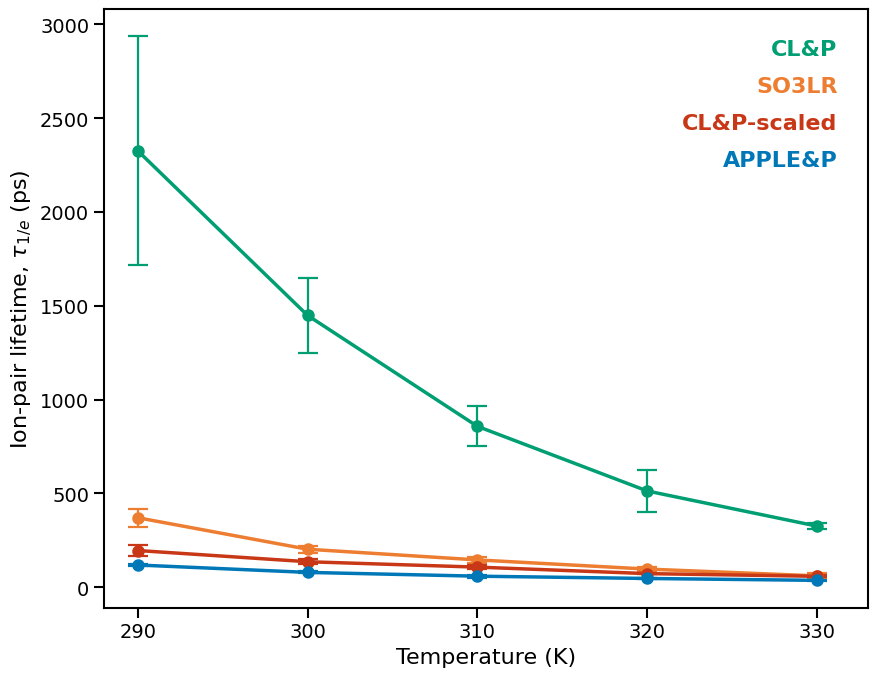

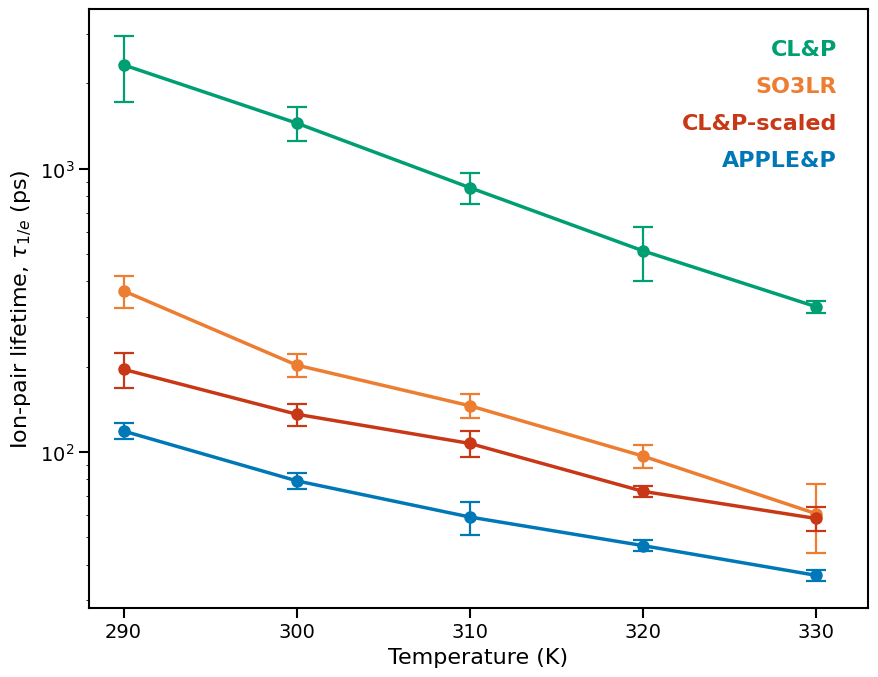

In [3]:
def style(ax, logy=False):
    ax.set(xlim=(288, 333), xticks=temps, xlabel='Temperature (K)',
           ylabel=r'Ion-pair lifetime, $\tau_{1/e}$ (ps)')
    if logy:
        ax.set_yscale('log')
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
    ax.tick_params(width=1.5, length=7)

def plot_lifetimes(logy=False):
    fig, ax = plt.subplots(figsize=(9, 7))
    for force_field in order:
        curve = summary[summary.force_field == force_field]
        crossed = curve[curve.tau_mean_ps.notna()]
        if len(crossed):
            ax.errorbar(crossed.temperature_K, crossed.tau_mean_ps, yerr=crossed.tau_seed_sd_ps.fillna(0),
                        color=colours[force_field], marker=markers[force_field], linestyle='-',
                        capsize=7, capthick=1.6, elinewidth=1.6)
        for row in curve[curve.lower_bound_ps.notna()].itertuples():
            ax.plot(row.temperature_K, row.lower_bound_ps, marker=markers[force_field],
                    color=colours[force_field], ms=8, linestyle='none')
            ax.annotate(f'>{row.lower_bound_ps:.0f}', (row.temperature_K, row.lower_bound_ps),
                        xytext=(5, 6), textcoords='offset points', fontsize=11)
    style(ax, logy=logy)
    for index, force_field in enumerate(order):
        ax.text(.96, .95 - .062 * index, labels[force_field], transform=ax.transAxes,
                color=colours[force_field], fontsize=16, fontweight='bold', ha='right', va='top')
    fig.tight_layout()
    suffix = '_logy' if logy else ''
    fig.savefig(figures / f'nearest_neighbor_ionpair_tau_1e_all_forcefields{suffix}.png',
                dpi=300, bbox_inches='tight', facecolor='white')
    return fig

plot_lifetimes(logy=True)
plt.show()
